# Where should this stock portfolio be held? A tax story in pictures

A stock-picking rule earns the same return before tax wherever it is kept. What changes is the tax, and the tax depends on the account (taxable, TFSA, RRSP) and on the bracket. This notebook measures what the account and the bracket cost one dividend portfolio, on one run of the history of a made-up Canadian market (so it works offline), and compares that cost with a single base case.

**The base case in every chart and table is to buy and hold the passive index in the same account, taxed the same way.** It is the grey dashed line, labelled "Buy and hold the index (after tax)", and the row labelled "Buy and hold the index" in every table. Nothing here is a forecast: the numbers show how the tax machinery behaves, not what you will earn. Not tax advice. Nothing is written to disk and nothing leaves your machine. The notebook takes about 30 seconds to run.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

try:
    import screenlab
except ImportError:                       # running from a git checkout without installing the package
    sys.path.insert(0, str(Path.cwd().parent.parent))
    import screenlab
from screenlab import Lab
from screenlab.taxes import CanadianTax, TaxConfig
from screenlab.tax_ca.api import marginal_rates
from screenlab.research import tax_plots as tp

%matplotlib inline
plt.rcParams["figure.dpi"] = 80
ACCOUNTS = ["taxable", "tfsa", "rrsp"]
NAME = tp.ACCOUNT_NAME                    # taxable -> Taxable, tfsa -> TFSA, rrsp -> RRSP
CAP = 100_000                             # starting money, dollars
PICKS = "stable_dividend"                 # a Globe and Mail screen: companies that pay a dividend and keep paying it
PICKS_NAME = "Dividend screen (stable_dividend)"
BASE = "Buy and hold the index (after tax)"

def tax_config(province="AB", other_income=90_000, rrsp_rate=0.30):
    # other_income: what you earn from work each year; it sets the bracket the portfolio's income is stacked on
    return TaxConfig(model=CanadianTax(province, other_income=other_income), account="taxable", rrsp_withdrawal_rate=rrsp_rate)

def show(fig):
    display(fig); plt.close(fig)

def say(text):                            # a paragraph written from the run's own numbers, so it cannot drift from them
    display(Markdown(text))

def usd(v):                               # dollars, with the dollar sign escaped so markdown does not read it as maths
    return f"\\${v:,.0f}"

def pts(v):                               # a fraction as points of growth a year
    return f"{100 * v:.2f}"

In [2]:
# All the runs of the notebook, once, so the summary can quote every number it uses.
lab = Lab.synthetic(freq="ME", n_stocks=150, years=12, seed=3)
rep = lab.account_compare([PICKS], tax=tax_config(), rebalance_months=12)
print(rep.data_card.line())
INDEX = rep.benchmark                     # the passive index of this market

def pair(account):                        # the screen and its base case in one account
    r = rep.reports[account]
    return {PICKS_NAME: r.results[PICKS], BASE: tp.index_result(r)}

# one row per account and holding: growth, tax drag and the dollars on CAP at the end
rows = []
for a in ACCOUNTS:
    for who, label in (("index", INDEX), ("screen", PICKS)):
        tb = rep.table[(rep.table["account"] == a) & (rep.table["name"] == label)].iloc[0]
        w = rep.reports[a].tax[label].iloc[-1]
        rows.append(dict(account=a, who=who, pre=tb["CAGR"], post=tb["AfterTaxCAGR"], drag=tb["TaxDrag/yr"],
                         excess=tb["AfterTaxExcess/yr"], taxpaid=tb["TaxPaid$"], divtax=tb["DivTax$"], gaintax=tb["GainTax$"],
                         pre_usd=w["wealth_pre_tax"], post_usd=w["wealth_after_tax"]))
A = pd.DataFrame(rows).set_index(["account", "who"])
A["tax_usd"] = A["pre_usd"] - A["post_usd"]
S, I = A.xs("screen", level="who"), A.xs("index", level="who")
YEARS = np.log(S.loc["tfsa", "pre_usd"] / CAP) / np.log(1 + S.loc["tfsa", "pre"])      # length of the run in years

# the RRSP convention: withdrawal rate 20-50%, and the last 3, 5, 8 and 11 years of the data
rows = []
for r in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    x = lab.account_compare([PICKS], tax=tax_config(rrsp_rate=r), rebalance_months=12, accounts=["taxable", "rrsp"]).table
    g = x.set_index(["kind", "account"])["AfterTaxCAGR"]
    rows.append({"rate": r, "screen_rrsp": g[("portfolio", "rrsp")], "screen_taxable": g[("portfolio", "taxable")],
                 "index_rrsp": g[("index", "rrsp")], "index_taxable": g[("index", "taxable")]})
by_rate = pd.DataFrame(rows)

end = rep.reports["taxable"].benchmark.index[-1]
rows = []
for years in (3, 5, 8, 11):
    start = str((end - pd.DateOffset(years=years)).date())
    x = lab.account_compare([PICKS], tax=tax_config(), rebalance_months=12, start=start).table
    g = x.set_index(["kind", "account"])["TaxDrag/yr"]
    rows.append({"years": years, "screen_taxable": g[("portfolio", "taxable")], "screen_rrsp": g[("portfolio", "rrsp")],
                 "index_taxable": g[("index", "taxable")], "index_rrsp": g[("index", "rrsp")]})
by_years = pd.DataFrame(rows)

# the bracket: other income of $30,000 / $90,000 / $200,000 in Alberta and British Columbia, taxable account
rows = []
for prov in ("AB", "BC"):
    for inc in (30_000, 90_000, 200_000):
        x = lab.account_compare([PICKS], tax=tax_config(prov, inc), rebalance_months=12, accounts=["taxable"]).table.set_index("kind")["AfterTaxCAGR"]
        rows.append({"province": prov, "other_income": inc, "screen": x["portfolio"], "index": x["index"]})
by_bracket = pd.DataFrame(rows)

Data: synthetic, 2000-01-31..2011-12-31, 150 names, benchmark SYN_CAPWT (total_return), PIT yes, delisted yes (33), survivorship -2.4%/yr


In [3]:
# The summary. Every number below is read from the runs above.
taxa, tfsa, rrsp = "taxable", "tfsa", "rrsp"
lo, hi = by_rate.iloc[0], by_rate.iloc[-1]
b = by_bracket.set_index(["province", "other_income"])
ab_lo, ab_hi = b.loc[("AB", 30_000)], b.loc[("AB", 200_000)]
gap_lo, gap_hi = ab_lo["screen"] - ab_lo["index"], ab_hi["screen"] - ab_hi["index"]
say(f'''
## Summary

**What the account costs.** A {usd(CAP)} investment in the dividend screen grew to {usd(S.loc[tfsa, "pre_usd"])} over {YEARS:.0f} years before tax ({100 * S.loc[tfsa, "pre"]:.2f}% a year), and the TFSA kept all of it. Tax took {usd(S.loc[taxa, "tax_usd"])} in a taxable account ({pts(S.loc[taxa, "drag"])} points of growth a year, leaving {usd(S.loc[taxa, "post_usd"])} or {100 * S.loc[taxa, "post"]:.2f}% a year) and {usd(S.loc[rrsp, "tax_usd"])} in the RRSP ({pts(S.loc[rrsp, "drag"])} points, leaving {usd(S.loc[rrsp, "post_usd"])} or {100 * S.loc[rrsp, "post"]:.2f}% a year), where the withdrawal is taxed at 30% and the deduction refund is left out. The TFSA was therefore worth {usd(S.loc[tfsa, "post_usd"] - S.loc[taxa, "post_usd"])} more than the taxable account and {usd(S.loc[tfsa, "post_usd"] - S.loc[rrsp, "post_usd"])} more than the RRSP. The base case, buying and holding the index in the same account, finished {usd(I.loc[taxa, "post_usd"] - S.loc[taxa, "post_usd"])} ahead of the screen in the taxable account, {usd(I.loc[tfsa, "post_usd"] - S.loc[tfsa, "post_usd"])} ahead in the TFSA and {usd(I.loc[rrsp, "post_usd"] - S.loc[rrsp, "post_usd"])} ahead in the RRSP, or {pts(-S.loc[taxa, "excess"])}, {pts(-S.loc[tfsa, "excess"])} and {pts(-S.loc[rrsp, "excess"])} points a year. The index itself gave up {pts(I.loc[taxa, "drag"])}, {pts(I.loc[tfsa, "drag"])} and {pts(I.loc[rrsp, "drag"])} points a year to tax in the three accounts. The account moved the screen's after-tax growth by {pts(S["post"].max() - S["post"].min())} points a year, and choosing the screen over the index cost {pts(-S["excess"].max())} to {pts(-S["excess"].min())} points a year in every account.

**What the assumptions change.** The RRSP result depended on the withdrawal rate: moving it from {lo["rate"]:.0%} to {hi["rate"]:.0%} took the screen's after-tax growth in the RRSP from {100 * lo["screen_rrsp"]:.2f}% to {100 * hi["screen_rrsp"]:.2f}% a year, and no rate in that range put it ahead of the taxable account ({100 * lo["screen_taxable"]:.2f}%). The holding period mattered more: the RRSP's tax drag was {pts(by_years.iloc[0]["screen_rrsp"])} points a year over the last {by_years.iloc[0]["years"]:.0f} years and {pts(by_years.iloc[-1]["screen_rrsp"])} over {by_years.iloc[-1]["years"]:.0f}. The bracket moved the taxable account less: raising other income from {usd(30_000)} to {usd(200_000)} in Alberta cut the screen's after-tax growth from {100 * ab_lo["screen"]:.2f}% to {100 * ab_hi["screen"]:.2f}% a year and the index's from {100 * ab_lo["index"]:.2f}% to {100 * ab_hi["index"]:.2f}%, which widened the screen's gap to the index from {pts(-gap_lo)} to {pts(-gap_hi)} points a year.
''')


## Summary

**What the account costs.** A \$100,000 investment in the dividend screen grew to \$216,094 over 11 years before tax (7.37% a year), and the TFSA kept all of it. Tax took \$17,274 in a taxable account (0.82 points of growth a year, leaving \$198,820 or 6.55% a year) and \$64,828 in the RRSP (3.48 points, leaving \$151,266 or 3.89% a year), where the withdrawal is taxed at 30% and the deduction refund is left out. The TFSA was therefore worth \$17,274 more than the taxable account and \$64,828 more than the RRSP. The base case, buying and holding the index in the same account, finished \$143,579 ahead of the screen in the taxable account, \$132,867 ahead in the TFSA and \$93,007 ahead in the RRSP, or 5.48, 4.86 and 4.70 points a year. The index itself gave up 0.20, 0.00 and 3.63 points a year to tax in the three accounts. The account moved the screen's after-tax growth by 3.48 points a year, and choosing the screen over the index cost 4.70 to 5.48 points a year in every account.

**What the assumptions change.** The RRSP result depended on the withdrawal rate: moving it from 20% to 50% took the screen's after-tax growth in the RRSP from 5.18% to 0.72% a year, and no rate in that range put it ahead of the taxable account (6.55%). The holding period mattered more: the RRSP's tax drag was 11.04 points a year over the last 3 years and 3.42 over 11. The bracket moved the taxable account less: raising other income from \$30,000 to \$200,000 in Alberta cut the screen's after-tax growth from 7.02% to 5.83% a year and the index's from 12.22% to 11.71%, which widened the screen's gap to the index from 5.20 to 5.88 points a year.


## 1. What each account costs

The summary put one number on each account. This section shows how those numbers arose, so that the later sections can change the assumptions one at a time and be read against the same picture. The question is how much of the dividend screen's before-tax return each account gives up to tax, and how that compares with buying and holding the index in the same account.

`stable_dividend` is one of the Globe and Mail screens: companies that pay a dividend and keep paying it. It was run on the synthetic Canadian market (150 stocks, 12 years of history), rebalanced once a year, for an Alberta resident with \$90,000 of other income a year and an RRSP withdrawn at a 30% tax rate. `account_compare` ran the identical screen and the passive index under each account and kept the yearly tax tables.

### Growth before and after tax

Each panel in Figure 1 is one account. The thin pale lines are growth before tax and the thick lines are growth after tax. The blue line is the dividend screen and the grey dashed line is the base case, the index bought and held in the same account. The vertical scale is logarithmic, so a straight climb is a steady yearly growth rate, and the number at the right edge of each line is the final multiple of the starting money.

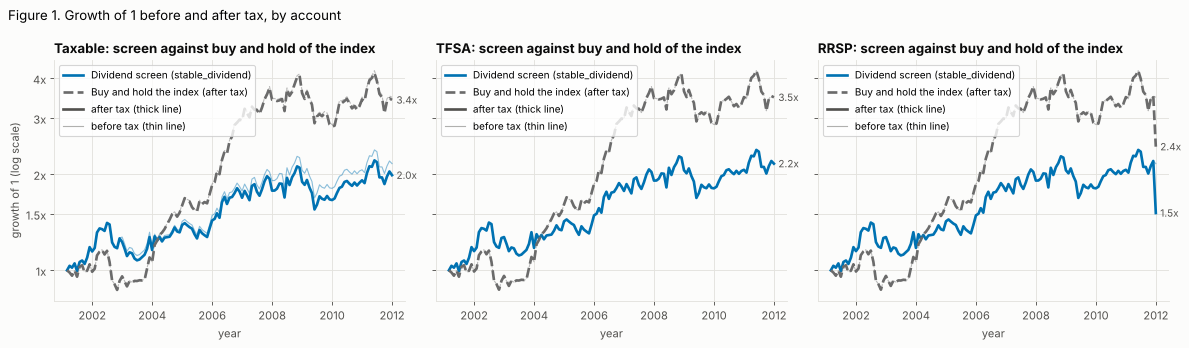

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, a in zip(axs, ACCOUNTS):
    tp.after_tax_curves(pair(a), ax=ax, title=f"{NAME[a]}: screen against buy and hold of the index")
    ax.set_xlabel("year")
for ax in axs[1:]:
    ax.set_ylabel("")
fig.suptitle("Figure 1. Growth of 1 before and after tax, by account", x=0.01, ha="left", fontsize=12)
fig.tight_layout(); show(fig)

### Tax paid, year by year

Figure 2 shows the dollars of tax paid in each year on a \$100,000 start, split by what was taxed: dividends, interest, capital gains (when the screen sells at a profit), foreign dividends and, in the RRSP, the withdrawal. A negative bar is a refund of an earlier year's tax from a loss carried back. The screen is all Canadian, so there is no foreign withholding to lose here; the notebook on foreign holdings covers that. Each panel has its own vertical scale, because the RRSP's single withdrawal bill is far larger than the yearly taxes of the taxable account. The grey dashed line with diamonds is the base case: the total tax paid each year by the index bought and held in the same account.

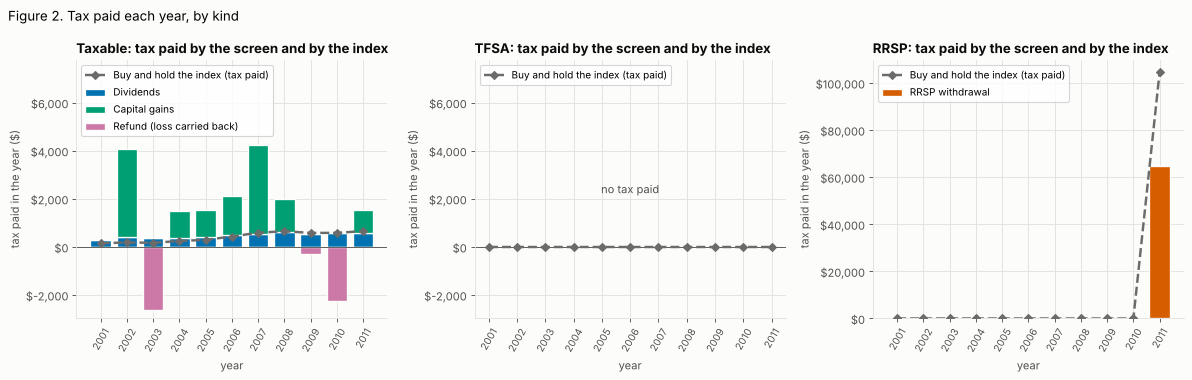

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, a in zip(axs, ACCOUNTS):
    r = rep.reports[a]
    tp.tax_paid_stack(r.results[PICKS], ax=ax, title=f"{NAME[a]}: tax paid by the screen and by the index",
                      baseline=tp.index_result(r), baseline_label="Buy and hold the index (tax paid)")
    ax.set_xlabel("year")
lo_, hi_ = axs[0].get_ylim()
axs[0].set_ylim(lo_, hi_ * 1.7)                        # headroom for the legend
axs[1].set_ylim(axs[0].get_ylim())                    # the TFSA panel on the taxable panel's scale
fig.suptitle("Figure 2. Tax paid each year, by kind", x=0.01, ha="left", fontsize=12)
fig.tight_layout(); show(fig)

### The tax drag, in points of growth a year

The tax drag is growth per year before tax minus growth per year after tax. In Figure 3 each group is an account, the pale bar is the screen before tax, the dark bar is the screen after tax, the bold number is the drag, and the grey dashed mark is the base case: the index's growth after tax in the same account. A bar that ends below the grey mark means the screen finished behind buying and holding the index. Table 1 gives the same figures with the dollars on \$100,000.

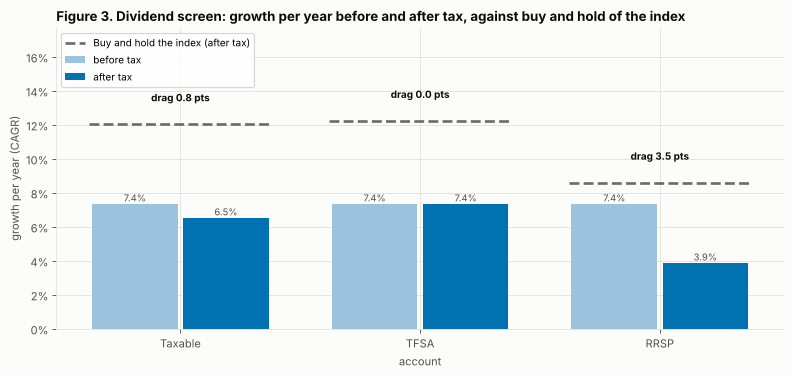

Table 1. Each holding in each account, on \$100,000 over 11 years


In [6]:
t = pd.DataFrame({"label": [NAME[a] for a in ACCOUNTS], "CAGR": S["pre"].loc[ACCOUNTS].to_numpy(), "AfterTaxCAGR": S["post"].loc[ACCOUNTS].to_numpy()})
fig, ax = plt.subplots(figsize=(10, 4.8))
tp.tax_drag_bars(t, ax=ax, title="Figure 3. Dividend screen: growth per year before and after tax, against buy and hold of the index",
                 baseline=I["post"].loc[ACCOUNTS].to_numpy(), baseline_label=BASE)
ax.set_xlabel("account")
fig.tight_layout(); show(fig)

tbl = A.reset_index()
tbl["holding"] = np.where(tbl["who"] == "index", "Buy and hold the index", "Dividend screen")
tbl["account"] = tbl["account"].map(NAME)
tbl = tbl.set_index(["account", "holding"])
tbl = tbl.loc[[(NAME[a], h) for a in ACCOUNTS for h in ("Buy and hold the index", "Dividend screen")],
              ["pre", "post", "drag", "excess", "pre_usd", "post_usd", "tax_usd"]]
tbl.columns = ["Growth a year before tax", "Growth a year after tax", "Tax drag (points a year)", "After-tax growth minus buy and hold",
               f"Final value before tax", f"Final value after tax", "Final value lost to tax"]
print(f"Table 1. Each holding in each account, on \\${CAP:,} over {YEARS:.0f} years")
tbl.style.format({c: "{:.2%}" for c in tbl.columns[:4]} | {c: "{:,.0f}" for c in tbl.columns[4:]}, na_rep="-")

In [7]:
say(f'''
### What the evidence says

The TFSA cost nothing: its drag was {pts(S.loc[tfsa, "drag"])} points for the screen and for the index, so after-tax growth equalled before-tax growth ({100 * S.loc[tfsa, "post"]:.2f}% and {100 * I.loc[tfsa, "post"]:.2f}%). The taxable account cost the screen {pts(S.loc[taxa, "drag"])} points a year, or {usd(S.loc[taxa, "tax_usd"])} of final value, and the index {pts(I.loc[taxa, "drag"])} points, or {usd(I.loc[taxa, "tax_usd"])}. The screen paid more because it sells: its gains tax was {usd(S.loc[taxa, "gaintax"])} and its dividend tax {usd(S.loc[taxa, "divtax"])}, while the index, bought and held, paid {usd(I.loc[taxa, "gaintax"])} of gains tax and {usd(I.loc[taxa, "divtax"])} of dividend tax. The RRSP cost the screen {pts(S.loc[rrsp, "drag"])} points a year and the index {pts(I.loc[rrsp, "drag"])}, nearly the same, because a 30% tax on the final balance is the same share of any portfolio; in dollars the index paid more ({usd(I.loc[rrsp, "tax_usd"])} against {usd(S.loc[rrsp, "tax_usd"])}) because its balance was larger.

Against the base case the account did not change the verdict. The screen trailed buying and holding the index by {pts(-S.loc[taxa, "excess"])} points a year in the taxable account, {pts(-S.loc[tfsa, "excess"])} in the TFSA and {pts(-S.loc[rrsp, "excess"])} in the RRSP, and it trailed before tax too ({100 * S.loc[tfsa, "pre"]:.2f}% against {100 * I.loc[tfsa, "pre"]:.2f}%, a shortfall of {pts(I.loc[tfsa, "pre"] - S.loc[tfsa, "pre"])} points). Tax moved that shortfall to between {pts(-S["excess"].max())} and {pts(-S["excess"].min())} points and never reversed it. In this run the choice of account moved the screen's result by {pts(S["post"].max() - S["post"].min())} points a year, and the choice of screen over the index moved it by more.
''')
assert (S["excess"] < 0).all() and S.loc[tfsa, "drag"] == 0 and I.loc[tfsa, "drag"] == 0
assert S["post"].max() - S["post"].min() < -S["excess"].min()


### What the evidence says

The TFSA cost nothing: its drag was 0.00 points for the screen and for the index, so after-tax growth equalled before-tax growth (7.37% and 12.22%). The taxable account cost the screen 0.82 points a year, or \$17,274 of final value, and the index 0.20 points, or \$6,563. The screen paid more because it sells: its gains tax was \$13,559 and its dividend tax \$5,175, while the index, bought and held, paid \$0 of gains tax and \$4,568 of dividend tax. The RRSP cost the screen 3.48 points a year and the index 3.63, nearly the same, because a 30% tax on the final balance is the same share of any portfolio; in dollars the index paid more (\$104,688 against \$64,828) because its balance was larger.

Against the base case the account did not change the verdict. The screen trailed buying and holding the index by 5.48 points a year in the taxable account, 4.86 in the TFSA and 4.70 in the RRSP, and it trailed before tax too (7.37% against 12.22%, a shortfall of 4.86 points). Tax moved that shortfall to between 4.70 and 5.48 points and never reversed it. In this run the choice of account moved the screen's result by 3.48 points a year, and the choice of screen over the index moved it by more.


## 2. How much of the RRSP result is convention

Section 1 showed the RRSP with the largest drag, but that result rests on two inputs the notebook supplies rather than measures: the tax rate at withdrawal (30%) and how long the money stays in. The question here is how much of the RRSP's drag is the convention and how much is the account. In this model the RRSP is tax-deferred: nothing is taxed while the money stays in, and on the last day the whole balance is taxed as ordinary income at one rate, `rrsp_withdrawal_rate`. The deduction a contributor gets on the way in is not modelled, so the principal is taxed on the way out without ever having been credited. That is conservative for the RRSP, and Section 4 returns to it.

### The withdrawal rate

Figure 4 shows after-tax growth per year for the screen and for the base case against the withdrawal rate. The taxable lines are flat because the withdrawal rate does not touch a taxable account; the RRSP lines fall as the rate rises. The grey dashed lines are the base case in each account: the index bought and held, taxed the same way.

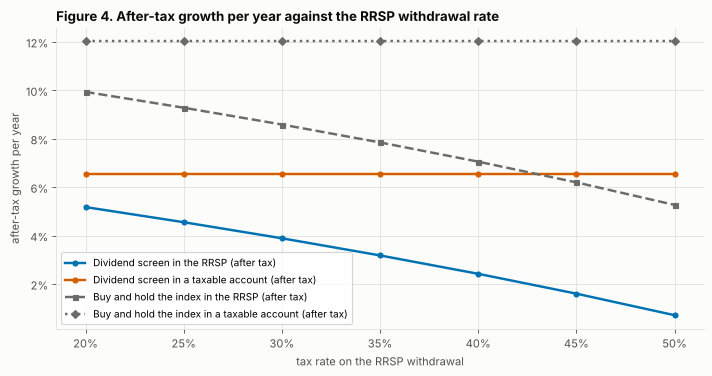

Table 2. After-tax growth per year against the withdrawal rate


,20%,25%,30%,35%,40%,45%,50%
"Buy and hold the index, taxable account",12.03%,12.03%,12.03%,12.03%,12.03%,12.03%,12.03%
Buy and hold the index in the RRSP,9.94%,9.28%,8.59%,7.85%,7.06%,6.20%,5.27%
"Dividend screen, taxable account",6.55%,6.55%,6.55%,6.55%,6.55%,6.55%,6.55%
Dividend screen in the RRSP,5.18%,4.56%,3.89%,3.19%,2.43%,1.61%,0.72%


In [8]:
fig, ax = plt.subplots(figsize=(9, 4.8))
tp.sensitivity_lines(by_rate, "rate", {"screen_rrsp": "Dividend screen in the RRSP (after tax)",
                     "screen_taxable": "Dividend screen in a taxable account (after tax)",
                     "index_rrsp": "Buy and hold the index in the RRSP (after tax)",
                     "index_taxable": "Buy and hold the index in a taxable account (after tax)"}, ax=ax,
                     baseline=["index_rrsp", "index_taxable"],
                     title="Figure 4. After-tax growth per year against the RRSP withdrawal rate",
                     xlabel="tax rate on the RRSP withdrawal", ylabel="after-tax growth per year")
ax.xaxis.set_major_formatter(lambda v, _: f"{100 * v:.0f}%")
fig.tight_layout(); show(fig)

tr = by_rate.set_index("rate").T
tr.index = ["Dividend screen in the RRSP", "Dividend screen, taxable account", "Buy and hold the index in the RRSP", "Buy and hold the index, taxable account"]
tr = tr.loc[["Buy and hold the index, taxable account", "Buy and hold the index in the RRSP", "Dividend screen, taxable account", "Dividend screen in the RRSP"]]
tr.columns = [f"{c:.0%}" for c in tr.columns]
print("Table 2. After-tax growth per year against the withdrawal rate")
tr.style.format("{:.2%}")

### The length of the holding

The same screen and the same 30% withdrawal rate were run again on the last 3, 5, 8 and 11 years of the data. Figure 5 shows the tax drag, the growth per year lost to tax, in each account. The withdrawal tax is a one-time bite out of the whole balance: at 30% it removes about 36% of the final value (that is, -ln 0.70) whatever the length of the run, so the same bite is spread over fewer years in a short run. The taxable account pays a little each year and does not behave that way. The grey dashed lines are again the base case, the index bought and held in the same account.

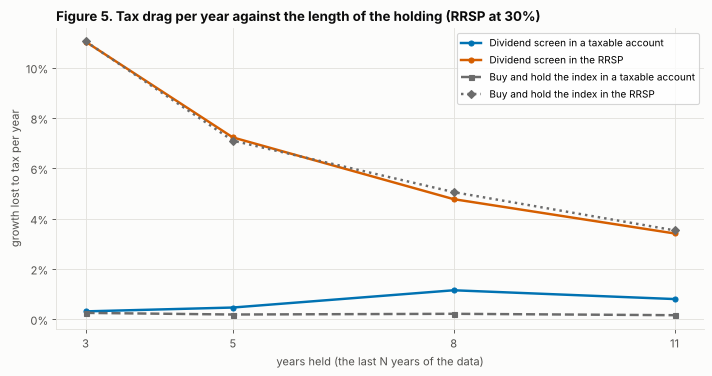

Table 3. Tax drag (points of growth a year) against the length of the holding


,last 3 years,last 5 years,last 8 years,last 11 years
"Buy and hold the index, taxable account",0.26%,0.19%,0.22%,0.16%
Buy and hold the index in the RRSP,11.06%,7.11%,5.06%,3.54%
"Dividend screen, taxable account",0.32%,0.47%,1.16%,0.81%
Dividend screen in the RRSP,11.04%,7.23%,4.78%,3.42%


In [9]:
fig, ax = plt.subplots(figsize=(9, 4.8))
tp.sensitivity_lines(by_years, "years", {"screen_taxable": "Dividend screen in a taxable account", "screen_rrsp": "Dividend screen in the RRSP",
                     "index_taxable": "Buy and hold the index in a taxable account", "index_rrsp": "Buy and hold the index in the RRSP"}, ax=ax,
                     baseline=["index_taxable", "index_rrsp"],
                     title="Figure 5. Tax drag per year against the length of the holding (RRSP at 30%)",
                     xlabel="years held (the last N years of the data)", ylabel="growth lost to tax per year")
ax.set_xticks(by_years["years"])
fig.tight_layout(); show(fig)

ty = by_years.set_index("years").T
ty.index = ["Dividend screen, taxable account", "Dividend screen in the RRSP", "Buy and hold the index, taxable account", "Buy and hold the index in the RRSP"]
ty = ty.loc[["Buy and hold the index, taxable account", "Buy and hold the index in the RRSP", "Dividend screen, taxable account", "Dividend screen in the RRSP"]]
ty.columns = [f"last {c} years" for c in ty.columns]
print("Table 3. Tax drag (points of growth a year) against the length of the holding")
ty.style.format("{:.2%}")

In [10]:
rt = 0.30
# the withdrawal rate at which the RRSP and the taxable account finish level: the RRSP keeps (1 - r) of the pre-tax balance
even_s = 1 - S.loc[taxa, "post_usd"] / S.loc[rrsp, "pre_usd"]
even_i = 1 - I.loc[taxa, "post_usd"] / I.loc[rrsp, "pre_usd"]
first, last = by_years.iloc[0], by_years.iloc[-1]
say(f'''
### What the evidence says

The withdrawal rate decided the RRSP's rank. Across rates of {lo["rate"]:.0%} to {hi["rate"]:.0%} the screen's after-tax growth in the RRSP fell from {100 * lo["screen_rrsp"]:.2f}% to {100 * hi["screen_rrsp"]:.2f}% a year, a swing of {pts(lo["screen_rrsp"] - hi["screen_rrsp"])} points, while the taxable account stayed at {100 * lo["screen_taxable"]:.2f}%. The base case behaved the same way, from {100 * lo["index_rrsp"]:.2f}% to {100 * hi["index_rrsp"]:.2f}% in the RRSP against a constant {100 * lo["index_taxable"]:.2f}% taxable. No rate in the range put the RRSP ahead of the taxable account for either holding. Because this model gives the RRSP no deduction refund, the RRSP finishes level with the taxable account only when the withdrawal rate equals the share of final value the taxable account lost to tax: {even_s:.1%} for the screen and {even_i:.1%} for the index. Every rate in Table 2 is above those two, so every one left the RRSP behind in this model, and that result is a property of the missing refund and not of the account.

The holding period mattered more than the rate. The RRSP's tax drag was {pts(first["screen_rrsp"])} points a year over the last {first["years"]:.0f} years and {pts(last["screen_rrsp"])} over {last["years"]:.0f}, a swing of {pts(first["screen_rrsp"] - last["screen_rrsp"])} points against {pts(lo["screen_rrsp"] - hi["screen_rrsp"])} for the whole range of rates, and {pts(first["index_rrsp"])} and {pts(last["index_rrsp"])} for the base case, so the screen and the index were hurt almost equally. The one-time withdrawal tax spread over the years, {-np.log(1 - rt) / first["years"]:.1%} a year over {first["years"]:.0f} years and {-np.log(1 - rt) / last["years"]:.1%} over {last["years"]:.0f}, is close to the measured drag. The taxable drag stayed between {pts(by_years["screen_taxable"].min())} and {pts(by_years["screen_taxable"].max())} points for the screen and between {pts(by_years["index_taxable"].min())} and {pts(by_years["index_taxable"].max())} for the index at every length. The RRSP's cost in this model is a function of the two assumed inputs, and the figures say nothing about what an RRSP is worth to someone who receives the deduction.
''')
assert (by_rate["screen_rrsp"] < by_rate["screen_taxable"]).all() and (by_rate["index_rrsp"] < by_rate["index_taxable"]).all()
assert by_years["screen_rrsp"].is_monotonic_decreasing
assert first["screen_rrsp"] - last["screen_rrsp"] > lo["screen_rrsp"] - hi["screen_rrsp"]


### What the evidence says

The withdrawal rate decided the RRSP's rank. Across rates of 20% to 50% the screen's after-tax growth in the RRSP fell from 5.18% to 0.72% a year, a swing of 4.46 points, while the taxable account stayed at 6.55%. The base case behaved the same way, from 9.94% to 5.27% in the RRSP against a constant 12.03% taxable. No rate in the range put the RRSP ahead of the taxable account for either holding. Because this model gives the RRSP no deduction refund, the RRSP finishes level with the taxable account only when the withdrawal rate equals the share of final value the taxable account lost to tax: 8.0% for the screen and 1.9% for the index. Every rate in Table 2 is above those two, so every one left the RRSP behind in this model, and that result is a property of the missing refund and not of the account.

The holding period mattered more than the rate. The RRSP's tax drag was 11.04 points a year over the last 3 years and 3.42 over 11, a swing of 7.63 points against 4.46 for the whole range of rates, and 11.06 and 3.54 for the base case, so the screen and the index were hurt almost equally. The one-time withdrawal tax spread over the years, 11.9% a year over 3 years and 3.2% over 11, is close to the measured drag. The taxable drag stayed between 0.32 and 1.16 points for the screen and between 0.16 and 0.26 for the index at every length. The RRSP's cost in this model is a function of the two assumed inputs, and the figures say nothing about what an RRSP is worth to someone who receives the deduction.


## 3. What the bracket and the province change

Sections 1 and 2 held the tax law fixed at an Alberta resident with \$90,000 of other income. The question now is how much the result moves when the bracket or the province changes, Section 2 treated the withdrawal rate as a free input, and part of what sets such a rate is the bracket, which is the subject here. The kinds of income are not taxed alike, and the screen and the index earn their money in different mixes: the index, bought and held, pays dividends and sells nothing, while the screen also sells.

### The tax on the next dollar

Figure 6 shows the tax on the next \$1 of each kind of income, stacked on top of other income, for Alberta (solid) and British Columbia (dashed). The grey wide dashed line is the base case: the index bought and held earns only eligible Canadian dividends, so its marginal rate is the eligible-dividend line. Very low incomes (under about \$30,000) are left off the vertical scale because there is little tax to measure there, and the black line is zero.

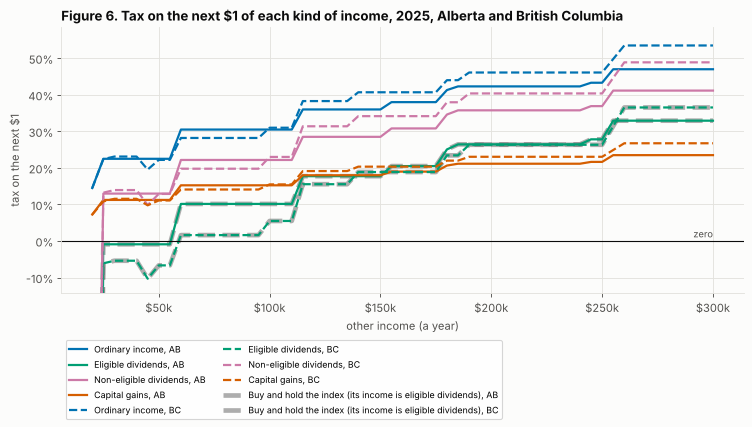

Table 4. Tax on the next dollar of each kind of income, by other income


In [11]:
fig, ax = plt.subplots(figsize=(9.5, 5.6))
tp.marginal_rate_curves(("AB", "BC"), 2025, range(20_000, 300_001, 5_000), ax=ax, baseline="eligible_dividend",
                        baseline_label="Buy and hold the index (its income is eligible dividends)",
                        title="Figure 6. Tax on the next \\$1 of each kind of income, 2025, Alberta and British Columbia")
fig.tight_layout(); show(fig)

pick = (30_000, 90_000, 200_000)
mr = {prov: pd.DataFrame([marginal_rates(prov, 2025, float(i)) for i in pick], index=pick) for prov in ("AB", "BC")}
kinds = [("eligible_dividend", "Buy and hold the index: eligible dividends"), ("ordinary", "Ordinary income (salary, interest, RRSP withdrawal)"),
         ("non_eligible_dividend", "Non-eligible dividends"), ("capital_gain", "Capital gains")]
mt = pd.DataFrame({(prov, f"${i // 1000}k"): [mr[prov].loc[i, k] for k, _ in kinds] for prov in ("AB", "BC") for i in pick}, index=[n for _, n in kinds])
print("Table 4. Tax on the next dollar of each kind of income, by other income")
mt.style.format("{:.1%}")

### The same screen at three incomes in two provinces

Only the taxable account is shown, because the TFSA pays no tax and the RRSP result depends on the withdrawal rate and not on today's bracket. Figure 7 and Table 5 give after-tax growth for the screen and for the base case, the index bought and held in the same account, at other income of \$30,000, \$90,000 and \$200,000 in Alberta and British Columbia.

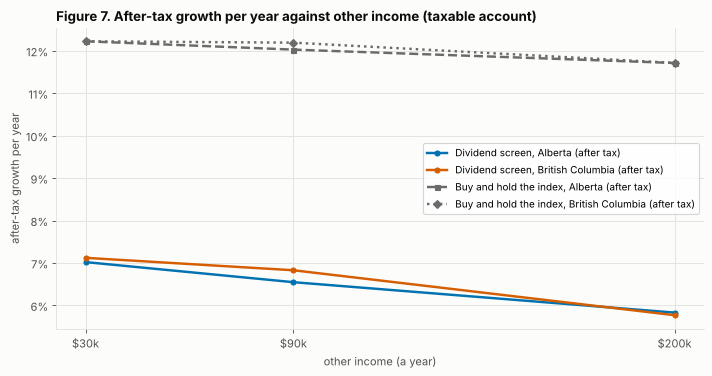

Table 5. After-tax growth per year, taxable account


In [12]:
wide = by_bracket.pivot(index="other_income", columns="province", values=["screen", "index"])
wide.columns = [f"{k}_{p}" for k, p in wide.columns]
wide = wide.reset_index()
fig, ax = plt.subplots(figsize=(9, 4.8))
tp.sensitivity_lines(wide, "other_income", {"screen_AB": "Dividend screen, Alberta (after tax)", "screen_BC": "Dividend screen, British Columbia (after tax)",
                     "index_AB": "Buy and hold the index, Alberta (after tax)", "index_BC": "Buy and hold the index, British Columbia (after tax)"}, ax=ax,
                     baseline=["index_AB", "index_BC"],
                     title="Figure 7. After-tax growth per year against other income (taxable account)",
                     xlabel="other income (a year)", ylabel="after-tax growth per year")
ax.set_xticks(wide["other_income"], ["\\$30k", "\\$90k", "\\$200k"])
fig.tight_layout(); show(fig)

bt = by_bracket.assign(gap=lambda d: d["screen"] - d["index"])
bt["province"] = bt["province"].map({"AB": "Alberta", "BC": "British Columbia"})
bt = bt.set_index(["province", "other_income"]).rename(columns={"index": "Buy and hold the index", "screen": "Dividend screen", "gap": "Screen minus buy and hold"})
print("Table 5. After-tax growth per year, taxable account")
bt.style.format("{:.2%}")

In [13]:
mrab = mr["AB"]
ratio = (mrab["capital_gain"] / mrab["ordinary"])
bb = b.loc[("BC", 90_000)]; ba = b.loc[("AB", 90_000)]
say(f'''
### What the evidence says

The kinds of income were taxed unlike each other, and the ranking changed with income. In Alberta, at {usd(pick[1])} of other income, the next dollar of ordinary income was taxed at {mrab.loc[pick[1], "ordinary"]:.1%}, of non-eligible dividends at {mrab.loc[pick[1], "non_eligible_dividend"]:.1%}, of capital gains at {mrab.loc[pick[1], "capital_gain"]:.1%} (about {ratio.loc[pick[1]]:.0%} of the ordinary rate) and of eligible dividends, the base case's income, at {mrab.loc[pick[1], "eligible_dividend"]:.1%}. The eligible-dividend rate was {mrab.loc[pick[0], "eligible_dividend"]:.1%} at {usd(pick[0])} and {mrab.loc[pick[2], "eligible_dividend"]:.1%} at {usd(pick[2])}, where it was above the capital-gains rate of {mrab.loc[pick[2], "capital_gain"]:.1%}. The base case therefore paid the lowest rate of any kind of income at low and middle incomes and a rising one at high incomes.

The taxable result fell as income rose, for the screen and the base case alike. In Alberta the screen went from {100 * ab_lo["screen"]:.2f}% to {100 * ab_hi["screen"]:.2f}% a year between {usd(30_000)} and {usd(200_000)}, a loss of {pts(ab_lo["screen"] - ab_hi["screen"])} points, and the base case from {100 * ab_lo["index"]:.2f}% to {100 * ab_hi["index"]:.2f}%, a loss of {pts(ab_lo["index"] - ab_hi["index"])} points. The screen lost more than the index to a higher bracket because it realized gains ({usd(S.loc[taxa, "gaintax"])} of gains tax in Section 1 against {usd(I.loc[taxa, "gaintax"])}), and its gap to the base case widened from {pts(-gap_lo)} to {pts(-gap_hi)} points a year. Changing the province moved the screen by {pts(abs(b.loc[("BC", 30_000), "screen"] - ab_lo["screen"]))} points at {usd(30_000)}, {pts(abs(bb["screen"] - ba["screen"]))} at {usd(90_000)} and {pts(abs(b.loc[("BC", 200_000), "screen"] - ab_hi["screen"]))} at {usd(200_000)}, and the index by {pts(abs(bb["index"] - ba["index"]))} at {usd(90_000)}, all less than the {pts(ab_lo["screen"] - ab_hi["screen"])} points the bracket moved the screen in Alberta. British Columbia's constants are partly unverified (see the end of the notebook), so the province differences are indicative only.
''')
assert (by_bracket.groupby("province")["screen"].diff().dropna() < 0).all() and (by_bracket.groupby("province")["index"].diff().dropna() <= 0).all()
assert gap_hi < gap_lo
assert all(abs(b.loc[("BC", k), "screen"] - b.loc[("AB", k), "screen"]) < ab_lo["screen"] - ab_hi["screen"] for k in (30_000, 90_000, 200_000))
assert mrab.loc[pick[0], "eligible_dividend"] < mrab.loc[pick[0], "capital_gain"] and mrab.loc[pick[2], "eligible_dividend"] > mrab.loc[pick[2], "capital_gain"]
assert mrab.loc[pick[1], "eligible_dividend"] < mrab.loc[pick[1], "capital_gain"]


### What the evidence says

The kinds of income were taxed unlike each other, and the ranking changed with income. In Alberta, at \$90,000 of other income, the next dollar of ordinary income was taxed at 30.5%, of non-eligible dividends at 22.2%, of capital gains at 15.2% (about 50% of the ordinary rate) and of eligible dividends, the base case's income, at 10.2%. The eligible-dividend rate was -0.9% at \$30,000 and 26.4% at \$200,000, where it was above the capital-gains rate of 21.2%. The base case therefore paid the lowest rate of any kind of income at low and middle incomes and a rising one at high incomes.

The taxable result fell as income rose, for the screen and the base case alike. In Alberta the screen went from 7.02% to 5.83% a year between \$30,000 and \$200,000, a loss of 1.19 points, and the base case from 12.22% to 11.71%, a loss of 0.51 points. The screen lost more than the index to a higher bracket because it realized gains (\$13,559 of gains tax in Section 1 against \$0), and its gap to the base case widened from 5.20 to 5.88 points a year. Changing the province moved the screen by 0.10 points at \$30,000, 0.28 at \$90,000 and 0.06 at \$200,000, and the index by 0.16 at \$90,000, all less than the 1.19 points the bracket moved the screen in Alberta. British Columbia's constants are partly unverified (see the end of the notebook), so the province differences are indicative only.


## 4. The three results together

The three sections each varied one thing. This section puts them side by side to ask which assumption moved the answer most, which is what decides how far to trust the ranking of accounts. Table 6 gives, for the screen and for the base case, the lowest and highest after-tax growth per year reached while each lever was varied and the others were held at their Section 1 values (Alberta, \$90,000, RRSP withdrawal at 30%).

In [14]:
def swing(name, s_vals, i_vals):
    return {"Lever varied": name, "Screen, lowest": s_vals.min(), "Screen, highest": s_vals.max(), "Screen, swing": s_vals.max() - s_vals.min(),
            "Buy and hold the index, lowest": i_vals.min(), "Buy and hold the index, highest": i_vals.max(), "Buy and hold the index, swing": i_vals.max() - i_vals.min()}
ab = by_bracket[by_bracket["province"] == "AB"]
at90 = by_bracket[by_bracket["other_income"] == 90_000]
levers = pd.DataFrame([
    swing("Account: taxable, TFSA or RRSP", S["post"], I["post"]),
    swing("RRSP withdrawal rate, 20% to 50%", by_rate["screen_rrsp"], by_rate["index_rrsp"]),
    swing("Other income, $30k to $200k (taxable, Alberta)", ab["screen"], ab["index"]),
    swing("Province, Alberta or British Columbia (taxable, $90k)", at90["screen"], at90["index"]),
]).set_index("Lever varied").sort_values("Screen, swing", ascending=False)
print("Table 6. How far each assumption moved after-tax growth per year")
levers.style.format("{:.2%}")

Table 6. How far each assumption moved after-tax growth per year


,"Screen, lowest","Screen, highest","Screen, swing","Buy and hold the index, lowest","Buy and hold the index, highest","Buy and hold the index, swing"
Lever varied,,,,,,
"RRSP withdrawal rate, 20% to 50%",0.72%,5.18%,4.46%,5.27%,9.94%,4.67%
"Account: taxable, TFSA or RRSP",3.89%,7.37%,3.48%,8.59%,12.22%,3.63%
"Other income, $30k to $200k (taxable, Alberta)",5.83%,7.02%,1.19%,11.71%,12.22%,0.51%
"Province, Alberta or British Columbia (taxable, $90k)",6.55%,6.83%,0.28%,12.03%,12.19%,0.16%


In [15]:
phrase = {"Account: taxable, TFSA or RRSP": "the choice of account", "RRSP withdrawal rate, 20% to 50%": "the RRSP withdrawal rate from 20% to 50%",
          "Other income, $30k to $200k (taxable, Alberta)": "other income from \\$30,000 to \\$200,000", "Province, Alberta or British Columbia (taxable, $90k)": "the province"}
ph = [phrase[k] for k in levers.index]
say(f'''
### What the evidence says

The size of the swing ranked the assumptions. For the screen, {ph[0]} moved after-tax growth by {pts(levers.iloc[0]["Screen, swing"])} points a year, {ph[1]} by {pts(levers.iloc[1]["Screen, swing"])}, {ph[2]} by {pts(levers.iloc[2]["Screen, swing"])} and {ph[3]} by {pts(levers.iloc[3]["Screen, swing"])}. The base case swung by {pts(levers.iloc[0]["Buy and hold the index, swing"])}, {pts(levers.iloc[1]["Buy and hold the index, swing"])}, {pts(levers.iloc[2]["Buy and hold the index, swing"])} and {pts(levers.iloc[3]["Buy and hold the index, swing"])} points under the same four levers, so the withdrawal rate and the account moved the two holdings by similar amounts and the bracket moved the screen about {levers.loc["Other income, $30k to $200k (taxable, Alberta)", "Screen, swing"] / levers.loc["Other income, $30k to $200k (taxable, Alberta)", "Buy and hold the index, swing"]:.1f} times as far as the index. Under no lever did the screen reach the base case: within each lever the screen's highest result stayed below the base case's lowest, by at least {pts((levers["Buy and hold the index, lowest"] - levers["Screen, highest"]).min())} points. What the notebook can say about where to hold this portfolio is therefore conditional: the TFSA kept the most in every comparison, the RRSP's place depended on a withdrawal rate and a refund that were assumed, and the shortfall against buying and holding the index, {pts(-S["excess"].max())} to {pts(-S["excess"].min())} points a year across the accounts, was set before tax by the choice of holding and was not removed by any account.
''')
assert (levers["Screen, highest"] < levers["Buy and hold the index, lowest"]).all()
assert levers["Screen, swing"].gt(0).all()


### What the evidence says

The size of the swing ranked the assumptions. For the screen, the RRSP withdrawal rate from 20% to 50% moved after-tax growth by 4.46 points a year, the choice of account by 3.48, other income from \$30,000 to \$200,000 by 1.19 and the province by 0.28. The base case swung by 4.67, 3.63, 0.51 and 0.16 points under the same four levers, so the withdrawal rate and the account moved the two holdings by similar amounts and the bracket moved the screen about 2.3 times as far as the index. Under no lever did the screen reach the base case: within each lever the screen's highest result stayed below the base case's lowest, by at least 0.09 points. What the notebook can say about where to hold this portfolio is therefore conditional: the TFSA kept the most in every comparison, the RRSP's place depended on a withdrawal rate and a refund that were assumed, and the shortfall against buying and holding the index, 4.70 to 5.48 points a year across the accounts, was set before tax by the choice of holding and was not removed by any account.


### What this ignores

* **Contribution room.** A TFSA or RRSP holds only what the room allows. Each account here was given all the money in turn.
* **The RRSP deduction refund.** The tax saved when you contribute is not modelled. It is the main reason an RRSP wins for someone in a higher bracket now than at retirement, and it is why the RRSP looks too weak here, especially over short periods. Modelling it needs your contribution amounts and your bracket in each year, which this notebook does not assume.
* **AMT, benefit clawbacks, the age credit, pension splitting** and the interaction of withdrawals with OAS are not in the model.
* **Tax tables.** Only the 2025 tables exist, and every year of the run uses them (the operation says so). Alberta numbers are the owner's reference; the **British Columbia constants are partly marked UNVERIFIED** in `tax_ca/tables.py` (the non-eligible dividend credit rate, the absence of a surtax or health premium, a possible change for 2026), so differences between British Columbia and Alberta are indicative only.
* **The data.** A synthetic Canadian market. The level of any return is meaningless; only the comparison between accounts, brackets and the base case is.
* **Not tax advice.** Check figures against the CRA and provincial sources for the year.